# D2C Customer Churn — Part 2: RFM Segmentation & Retention Strategy

**Snapshot date:** `2025-09-30`  
**RFM window:** Full pre-snapshot order history for Recency; 180 days for Frequency & Monetary  
**Additional signals:** Web/app activity, support tickets, return behaviour, discount usage, loyalty tier  

---
### Notebook Structure
1. Setup & Data Loading  
2. RFM Feature Engineering  
3. RFM Scoring (Quintile-based, 1–5)  
4. Additional Behavioural Signals  
5. Segment Assignment Logic  
6. Segment Profiles & Visualisations  
7. Budget Prioritisation  
8. Export — `segments.csv`

## 1. Setup & Data Loading

In [25]:
import warnings
warnings.filterwarnings('ignore')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats

# ── Display ───────────────────────────────────────────────────────────────────
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
FIG_DPI = 130

# ── Constants ─────────────────────────────────────────────────────────────────
SNAPSHOT     = pd.Timestamp('2025-09-30')
RFM_WINDOW   = 180          # days for frequency & monetary
RFM_START    = SNAPSHOT - pd.Timedelta(days=RFM_WINDOW)

# ── Data path ─────────────────────────────────────────────────────────────────
from pathlib import Path

PROJECT_ROOT = Path.cwd()

# If notebook is executed from notebooks/01_eda
if PROJECT_ROOT.name == "02_rfm":
    PROJECT_ROOT = PROJECT_ROOT.parent.parent
elif PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Data directory not found: {DATA_DIR}\n"
        f"Expected project root: {PROJECT_ROOT}"
    )

# print("Project root:", PROJECT_ROOT)
# print("Data directory:", DATA_DIR)

# ── Output directories ────────────────────────────────────────────────────────
rfm_output_dir = os.path.join(PROJECT_ROOT, "outputs", "rfm")
rfm_charts_dir = os.path.join(rfm_output_dir, "charts")
rfm_summary_metrics_dir = os.path.join(rfm_output_dir, "summary_metrics")
rfm_tables_dir = os.path.join(rfm_output_dir, "tables")

for folder in [rfm_charts_dir, rfm_summary_metrics_dir, rfm_tables_dir]:
    os.makedirs(folder, exist_ok=True)

def load(f): return pd.read_csv(os.path.join(DATA_DIR, f))

print('Setup complete.')
print(f'RFM window: {RFM_START.date()} → {SNAPSHOT.date()} ({RFM_WINDOW} days)')

Setup complete.
RFM window: 2025-04-03 → 2025-09-30 (180 days)


In [26]:
customers     = load('customers.csv')
orders        = load('orders.csv')
tickets       = load('support_tickets.csv')
web           = load('web_events_snapshot.csv')
interventions = load('intervention_history.csv')
labels        = load('churn_labels.csv')

customers['signup_date']   = pd.to_datetime(customers['signup_date'])
orders['order_date']       = pd.to_datetime(orders['order_date'])
tickets['ticket_date']     = pd.to_datetime(tickets['ticket_date'])

# ── Filter: pre-snapshot, de-duplicated orders ────────────────────────────────
orders_pre = (
    orders[
        (orders['order_date'] <= SNAPSHOT) &
        (~orders['order_id'].str.endswith('_DUP'))
    ].copy()
)
orders_rfm = orders_pre[orders_pre['order_date'] >= RFM_START].copy()

print(f'All pre-snapshot orders (de-duped):  {len(orders_pre):,}')
print(f'Orders in 180-day RFM window:        {len(orders_rfm):,}')
print(f'Customers in universe:               {len(customers):,}')

All pre-snapshot orders (de-duped):  8,128
Orders in 180-day RFM window:        3,827
Customers in universe:               2,400


## 2. RFM Feature Engineering

In [27]:
# ── Recency: days since last order (full history) ─────────────────────────────
recency_df = (
    orders_pre.groupby('customer_id')['order_date']
    .max()
    .reset_index()
    .rename(columns={'order_date': 'last_order_date'})
)
recency_df['recency_days'] = (SNAPSHOT - recency_df['last_order_date']).dt.days

# ── Frequency & Monetary: 180-day window ─────────────────────────────────────
fm_df = (
    orders_rfm.groupby('customer_id')
    .agg(
        frequency_180d  = ('order_id',    'count'),
        monetary_180d   = ('gross_amount', 'sum'),
        avg_order_value = ('gross_amount', 'mean'),
    )
    .reset_index()
)

# ── Additional order-level features (180-day window) ─────────────────────────
extra_df = (
    orders_rfm.groupby('customer_id')
    .agg(
        return_rate_180d      = ('returned',     'mean'),
        avg_discount_180d     = ('discount_pct', 'mean'),
        avg_rating_180d       = ('rating',       'mean'),
        category_diversity    = ('category',     'nunique'),
        total_quantity_180d   = ('quantity',     'sum'),
    )
    .reset_index()
)

# ── Full-history total spend (for absolute value context) ─────────────────────
lifetime_df = (
    orders_pre.groupby('customer_id')['gross_amount']
    .sum().reset_index()
    .rename(columns={'gross_amount': 'lifetime_spend'})
)

# ── Days since signup ─────────────────────────────────────────────────────────
customers['days_since_signup'] = (SNAPSHOT - customers['signup_date']).dt.days

print('Recency df:', recency_df.shape)
print('FM df:     ', fm_df.shape)
print('Extra df:  ', extra_df.shape)

Recency df: (2400, 3)
FM df:      (2098, 4)
Extra df:   (2098, 6)


In [28]:
# ── Support ticket signals ────────────────────────────────────────────────────
ticket_df = (
    tickets.groupby('customer_id')
    .agg(
        ticket_count_all      = ('ticket_id',       'count'),
        avg_sentiment         = ('sentiment_score',  'mean'),
        neg_ticket_rate       = ('sentiment_score',  lambda x: (x < 0).mean()),
        avg_resolution_hrs    = ('resolution_hours', 'mean'),
        reopened_rate         = ('reopened',         'mean'),
        n_product_reaction    = ('issue_type',       lambda x: (x == 'product_reaction').sum()),
        n_refund_delay        = ('issue_type',       lambda x: (x == 'refund_delay').sum()),
    )
    .reset_index()
)

# ── Web / app activity ────────────────────────────────────────────────────────
web_df = web.drop(columns=['snapshot_date'])

# ── Build master RFM table ───────────────────────────────────────────────────
rfm = customers[['customer_id','loyalty_tier','acquisition_channel',
                 'preferred_category','days_since_signup','marketing_consent',
                 'city_tier','age_group']].copy()

rfm = (
    rfm
    .merge(recency_df[['customer_id','recency_days','last_order_date']], on='customer_id', how='left')
    .merge(fm_df,        on='customer_id', how='left')
    .merge(extra_df,     on='customer_id', how='left')
    .merge(lifetime_df,  on='customer_id', how='left')
    .merge(ticket_df,    on='customer_id', how='left')
    .merge(web_df,       on='customer_id', how='left')
    .merge(interventions[['customer_id','last_campaign_received','manual_priority_bucket']],
           on='customer_id', how='left')
    .merge(labels[['customer_id','churn_next_60d','split']], on='customer_id', how='left')
)

# Fill nulls for customers with no 180-day orders or no tickets
rfm['frequency_180d']    = rfm['frequency_180d'].fillna(0).astype(int)
rfm['monetary_180d']     = rfm['monetary_180d'].fillna(0)
rfm['ticket_count_all']  = rfm['ticket_count_all'].fillna(0).astype(int)
rfm['return_rate_180d']  = rfm['return_rate_180d'].fillna(0)
rfm['avg_discount_180d'] = rfm['avg_discount_180d'].fillna(rfm['avg_discount_180d'].median())
rfm['has_ticket']        = (rfm['ticket_count_all'] > 0).astype(int)
rfm['neg_ticket_rate']   = rfm['neg_ticket_rate'].fillna(0)

print(f'Master RFM table: {rfm.shape}')
rfm[['customer_id','recency_days','frequency_180d','monetary_180d',
     'return_rate_180d','avg_discount_180d','sessions_30d','ticket_count_all']].describe().round(2)

Master RFM table: (2400, 39)


,recency_days,frequency_180d,monetary_180d,return_rate_180d,avg_discount_180d,sessions_30d,ticket_count_all
count,2400.0000,2400.0000,2400.0000,2400.0000,2400.0000,2400.0000,2400.0000
mean,87.3800,1.5900,1183.7900,0.0600,0.2800,5.4600,0.8000
std,80.1400,1.1800,1057.6200,0.2000,0.1000,4.4000,0.9800
min,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
25%,25.0000,1.0000,449.2700,0.0000,0.2200,2.0000,0.0000
50%,66.0000,1.0000,911.8800,0.0000,0.2800,5.0000,1.0000
75%,129.0000,2.0000,1681.5100,0.0000,0.3400,8.0000,1.0000
max,562.0000,8.0000,11655.3100,1.0000,0.7000,25.0000,6.0000


## 3. RFM Scoring (Quintile-based, 1–5)

> **R score:** Lower recency → higher score (5 = most recent)  
> **F score:** Higher frequency → higher score  
> **M score:** Higher monetary → higher score  
> Customers with 0 frequency in the 180d window receive F=1, M=1.

In [29]:
def robust_quintile_score(series, ascending=True, n=5):
    """
    Assign 1-n scores using percentile rank, bypassing qcut bin-edge
    collisions entirely. Works even when many values are identical.
    ascending=True  → high value gets high score (Frequency, Monetary)
    ascending=False → low  value gets high score (Recency)
    """
    pct = series.rank(pct=True, method='average')
    if not ascending:
        pct = 1 - pct
    # Map percentile to 1-n bands
    score = np.ceil(pct * n).clip(1, n)
    return score.astype(float)

# ── Recency: lower days = better = higher score ───────────────────────────────
rfm['R'] = robust_quintile_score(rfm['recency_days'], ascending=False)

# ── Frequency (180d): higher = better; zero-order customers get F=1 ───────────
mask_f = rfm['frequency_180d'] > 0
rfm['F'] = 1.0
rfm.loc[mask_f, 'F'] = robust_quintile_score(rfm.loc[mask_f, 'frequency_180d'], ascending=True)

# ── Monetary (180d): higher = better; zero-spend customers get M=1 ─────────────
mask_m = rfm['monetary_180d'] > 0
rfm['M'] = 1.0
rfm.loc[mask_m, 'M'] = robust_quintile_score(rfm.loc[mask_m, 'monetary_180d'], ascending=True)

# ── Composite RFM score & label ───────────────────────────────────────────────
rfm[['R','F','M']] = rfm[['R','F','M']].astype(float)
rfm['rfm_score']   = rfm[['R','F','M']].mean(axis=1).round(2)
rfm['rfm_label']   = rfm['R'].astype(int).astype(str) + rfm['F'].astype(int).astype(str) + rfm['M'].astype(int).astype(str)

print('RFM score distribution:')
print(rfm[['R','F','M','rfm_score']].describe().round(2))
print('\nR score value counts:', rfm['R'].value_counts().sort_index().to_dict())
print('F score value counts:', rfm['F'].value_counts().sort_index().to_dict())
print('M score value counts:', rfm['M'].value_counts().sort_index().to_dict())

RFM score distribution:
              R         F         M  rfm_score
count 2400.0000 2400.0000 2400.0000  2400.0000
mean     3.0000    2.9100    2.7500     2.8900
std      1.4100    1.3900    1.4800     1.1800
min      1.0000    1.0000    1.0000     1.0000
25%      2.0000    2.0000    1.0000     2.0000
50%      3.0000    2.0000    3.0000     3.0000
75%      4.0000    4.0000    4.0000     4.0000
max      5.0000    5.0000    5.0000     5.0000

R score value counts: {1.0: 480, 2.0: 483, 3.0: 476, 4.0: 484, 5.0: 477}
F score value counts: {1.0: 302, 2.0: 1075, 4.0: 579, 5.0: 444}
M score value counts: {1.0: 721, 2.0: 420, 3.0: 419, 4.0: 420, 5.0: 420}


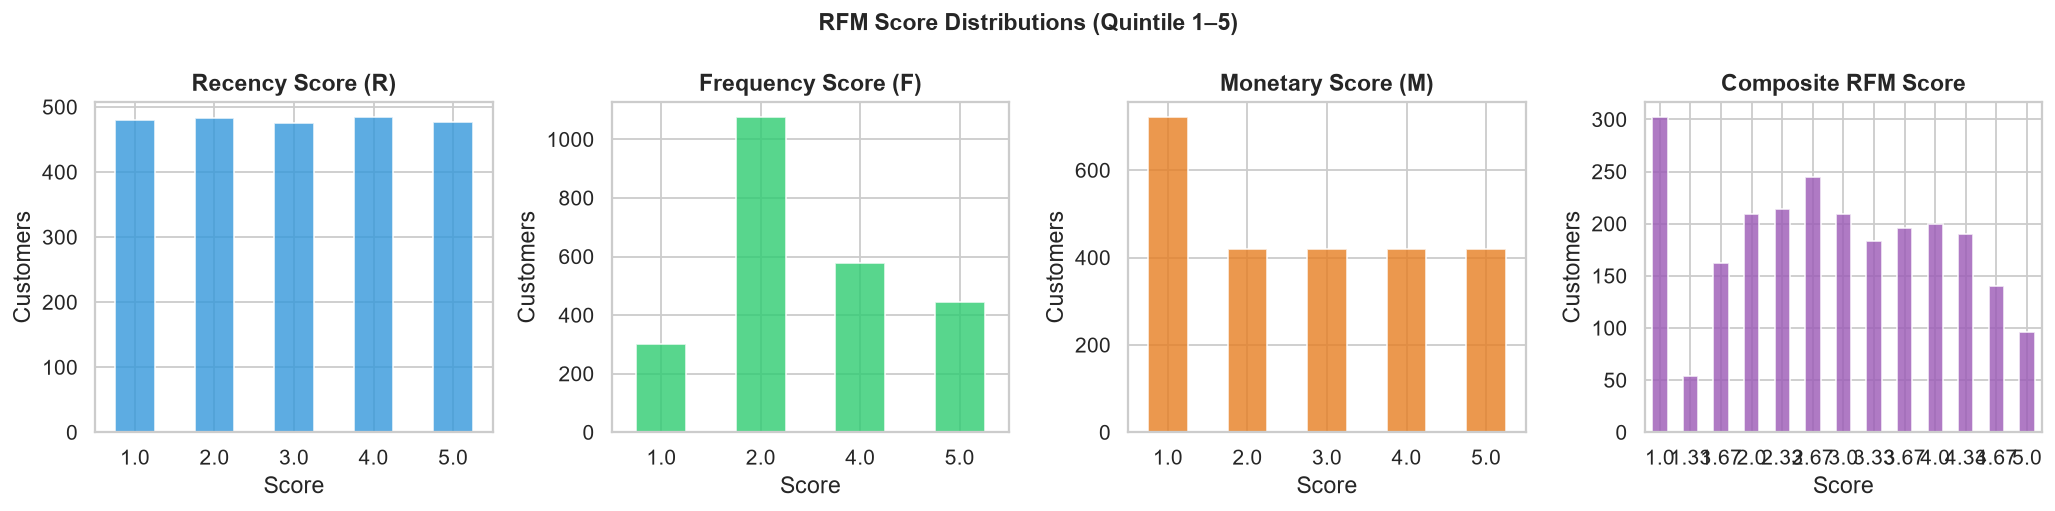

Saved: chart_01_rfm_score_distributions.png


In [30]:
# ── RFM score distribution plots ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(16, 4), dpi=FIG_DPI)

for ax, col, title, color in zip(
    axes,
    ['R', 'F', 'M', 'rfm_score'],
    ['Recency Score (R)', 'Frequency Score (F)', 'Monetary Score (M)', 'Composite RFM Score'],
    ['#3498db', '#2ecc71', '#e67e22', '#9b59b6']
):
    rfm[col].value_counts().sort_index().plot(kind='bar', ax=ax, color=color, alpha=0.8, rot=0)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Score')
    ax.set_ylabel('Customers')

plt.suptitle('RFM Score Distributions (Quintile 1–5)', fontsize=13, fontweight='bold')
plt.tight_layout()
file_path = os.path.join(rfm_charts_dir, "chart_01_rfm_score_distributions.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_01_rfm_score_distributions.png')

## 4. Additional Behavioural Signals

Six signals beyond RFM are computed and used in segment assignment:

| Signal | Source | Use |
|---|---|---|
| `web_engagement_score` | `web_events_snapshot.csv` | Composite of sessions, views, adds |
| `discount_hunter_flag` | `orders.csv` | avg discount > 40% |
| `high_return_flag` | `orders.csv` | return rate > 33% |
| `unhappy_flag` | `support_tickets.csv` | neg ticket rate > 50% OR product_reaction ticket |
| `loyalty_enrolled` | `customers.csv` | whether customer is in loyalty programme |
| `new_customer_flag` | `customers.csv` | signup within last 90 days |

In [31]:
# ── Web engagement composite score (normalised 0-1) ───────────────────────────
# Uses sessions, product_views, cart_adds, wishlist_adds, email_opens
web_cols = ['sessions_30d','product_views_30d','cart_adds_30d','wishlist_adds_30d','email_opens_30d']
for c in web_cols:
    rfm[c] = rfm[c].fillna(0)

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
rfm['web_engagement_score'] = scaler.fit_transform(rfm[web_cols]).mean(axis=1).round(4)

# ── Binary signal flags ───────────────────────────────────────────────────────
rfm['discount_hunter_flag'] = (rfm['avg_discount_180d'] >= 0.40).astype(int)
rfm['high_return_flag']     = (rfm['return_rate_180d']  >= 0.33).astype(int)
rfm['unhappy_flag']         = (
    (rfm['neg_ticket_rate'] >= 0.50) |
    (rfm['n_product_reaction'].fillna(0) >= 1)
).astype(int)
rfm['loyalty_enrolled']     = rfm['loyalty_tier'].notna().astype(int)
rfm['new_customer_flag']    = (rfm['days_since_signup'] <= 90).astype(int)
rfm['low_web_flag']         = (rfm['sessions_30d'] == 0).astype(int)

print('Signal flag summary:')
flag_cols = ['discount_hunter_flag','high_return_flag','unhappy_flag',
             'loyalty_enrolled','new_customer_flag','low_web_flag']
print(rfm[flag_cols].sum().rename('count').to_frame().assign(pct=lambda x: (x['count']/len(rfm)*100).round(1)).to_string())

Signal flag summary:
                      count     pct
discount_hunter_flag    298 12.4000
high_return_flag        212  8.8000
unhappy_flag           1065 44.4000
loyalty_enrolled       1014 42.2000
new_customer_flag       298 12.4000
low_web_flag            190  7.9000


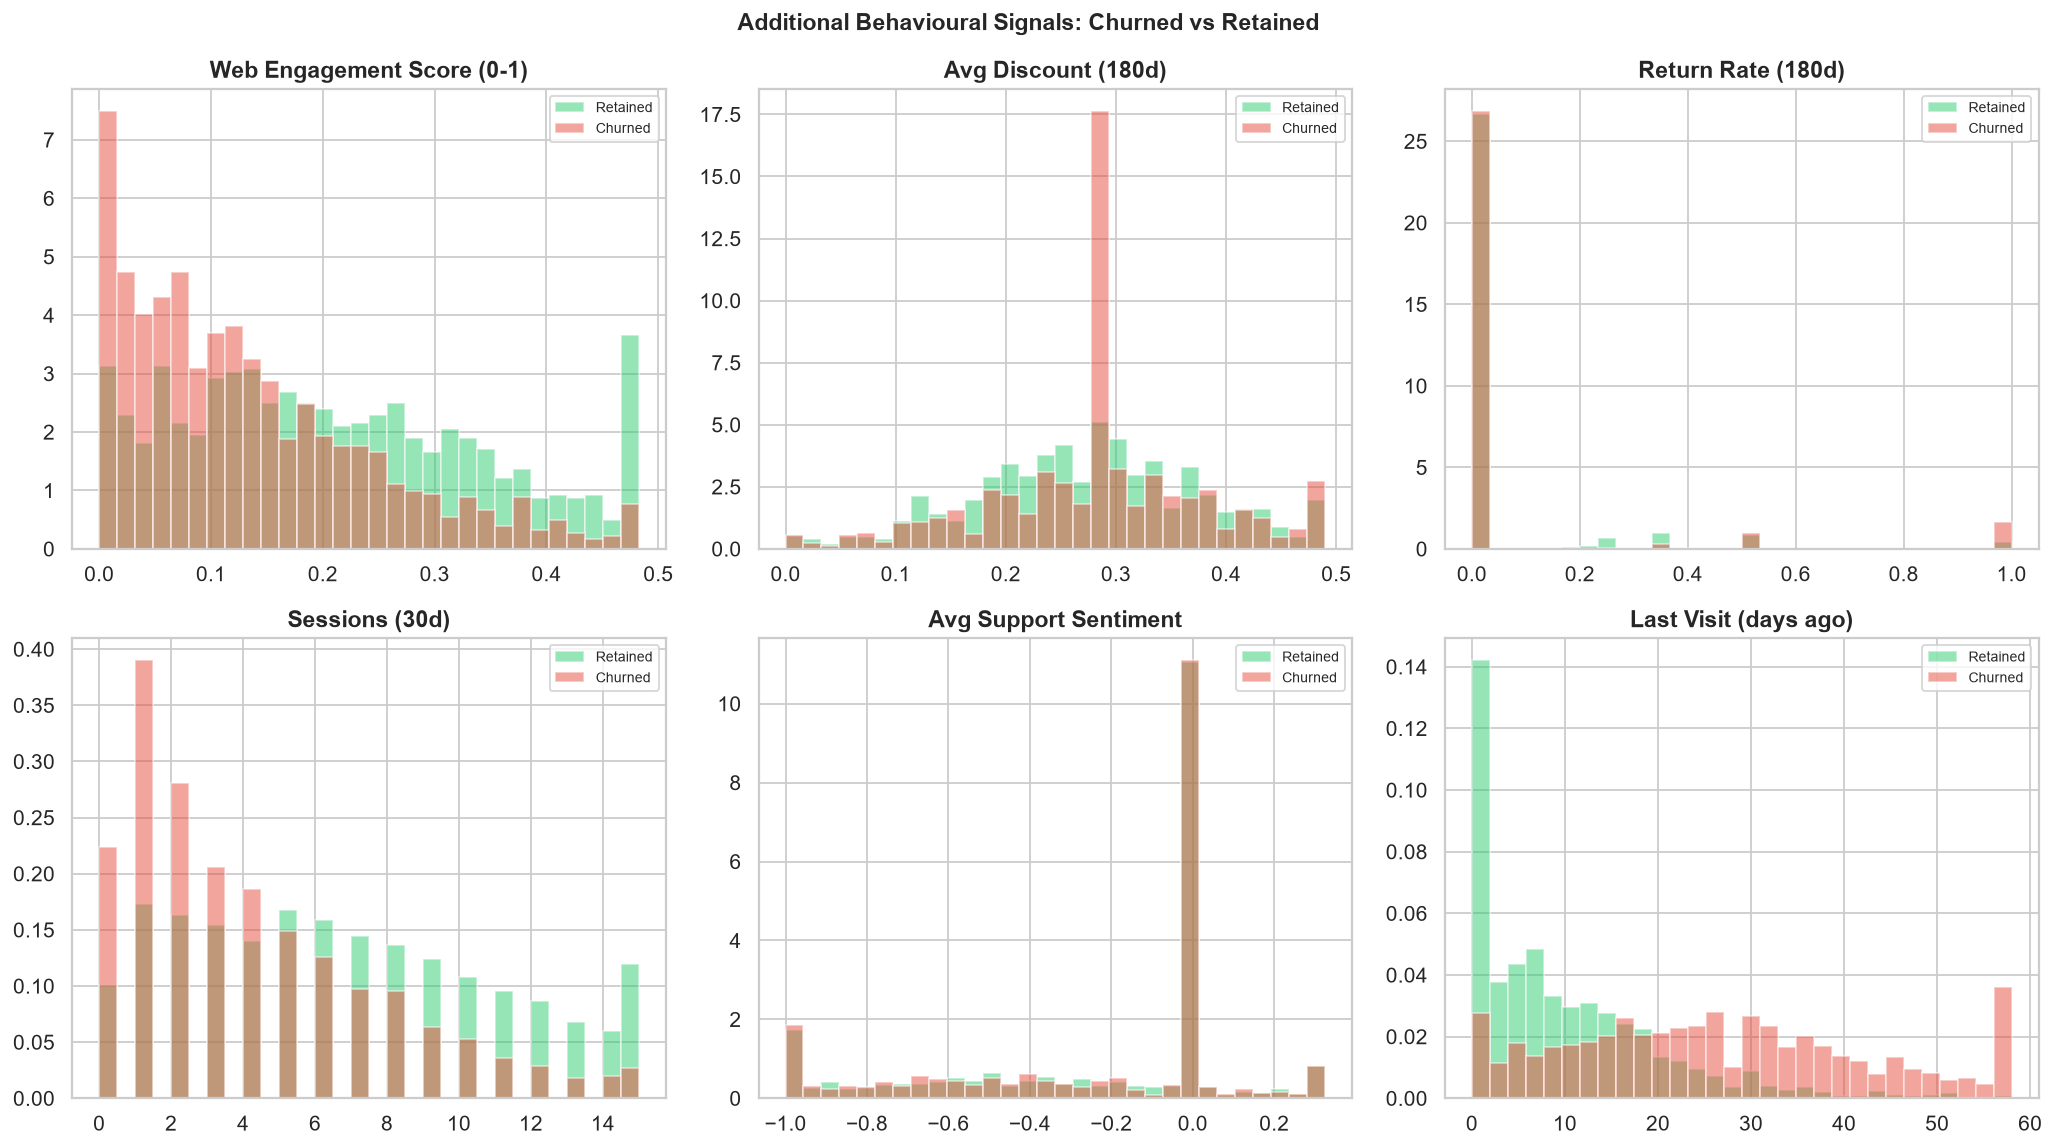

Saved: chart_02_additional_signals.png


In [32]:
# ── Visualise the key additional signals by churn status ─────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 9), dpi=FIG_DPI)
signal_plots = [
    ('web_engagement_score', 'Web Engagement Score (0-1)', '#3498db'),
    ('avg_discount_180d',    'Avg Discount (180d)',        '#e67e22'),
    ('return_rate_180d',     'Return Rate (180d)',         '#e74c3c'),
    ('sessions_30d',         'Sessions (30d)',             '#2ecc71'),
    ('avg_sentiment',        'Avg Support Sentiment',      '#9b59b6'),
    ('last_visit_days_ago',  'Last Visit (days ago)',      '#1abc9c'),
]
for ax, (col, title, color) in zip(axes.flat, signal_plots):
    data = rfm[col].fillna(0)
    clip = data.quantile(0.97)
    for churn_val, label, c in [(0,'Retained','#2ecc71'),(1,'Churned','#e74c3c')]:
        sub = rfm[rfm['churn_next_60d']==churn_val][col].fillna(0).clip(upper=clip)
        ax.hist(sub, bins=30, alpha=0.5, label=label, color=c, density=True)
    ax.set_title(title, fontweight='bold')
    ax.legend(fontsize=8)

plt.suptitle('Additional Behavioural Signals: Churned vs Retained', fontsize=13, fontweight='bold')
plt.tight_layout()
file_path = os.path.join(rfm_charts_dir, "chart_02_additional_signals.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_02_additional_signals.png')

## 5. Segment Assignment Logic

Segments are assigned using a **priority-ordered rule cascade** — each customer is assigned to the first segment whose rules they satisfy. Rules combine RFM scores with behavioural flags.

### Segment Definitions

| Priority | Segment | Core RFM Rule | Behavioural Qualifier |
|---|---|---|---|
| 1 | **New Customers** | Any RFM | Signup ≤ 90 days ago |
| 2 | **Champions** | R≥4, F≥4, M≥4 | No unhappy flag |
| 3 | **Loyal Customers** | F≥4, M≥3, R≥3 | Not Champions |
| 4 | **High-Value Unhappy** | M≥4 OR lifetime_spend top 25% | unhappy_flag=1 OR high_return_flag=1 |
| 5 | **At-Risk** | R≤2, was previously F≥3 or M≥3 | — |
| 6 | **Discount Hunters** | Any R/F | discount_hunter_flag=1, M≤3 |
| 7 | **Dormant** | R≤2, F≤2, M≤2 | — |
| 8 | **Promising** | R≥3, F≤2 | New-ish customers (91–180 days) OR low frequency |
| 9 | **Others / Occasional** | Everything else | — |

In [33]:
def assign_segment(row):
    R, F, M = row['R'], row['F'], row['M']
    rfm_s   = row['rfm_score']

    # ── 1. New Customers ──────────────────────────────────────────────────────
    if row['new_customer_flag'] == 1:
        return 'New Customers'

    # ── 2. Champions ──────────────────────────────────────────────────────────
    if R >= 4 and F >= 4 and M >= 4 and row['unhappy_flag'] == 0:
        return 'Champions'

    # ── 3. Loyal Customers ────────────────────────────────────────────────────
    if F >= 4 and M >= 3 and R >= 3:
        return 'Loyal Customers'

    # ── 4. High-Value Unhappy ─────────────────────────────────────────────────
    if (M >= 4 or row['lifetime_spend'] >= row['lifetime_p75']) and \
       (row['unhappy_flag'] == 1 or row['high_return_flag'] == 1):
        return 'High-Value Unhappy'

    # ── 5. At-Risk ────────────────────────────────────────────────────────────
    if R <= 2 and (F >= 3 or M >= 3):
        return 'At-Risk'

    # ── 6. Discount Hunters ───────────────────────────────────────────────────
    if row['discount_hunter_flag'] == 1 and M <= 3:
        return 'Discount Hunters'

    # ── 7. Dormant ────────────────────────────────────────────────────────────
    if R <= 2 and F <= 2 and M <= 2:
        return 'Dormant'

    # ── 8. Promising ──────────────────────────────────────────────────────────
    if R >= 3 and F <= 2:
        return 'Promising'

    # ── 9. Occasional Buyers ──────────────────────────────────────────────────
    return 'Occasional Buyers'


# Pre-compute lifetime_spend 75th percentile for use in function
p75 = rfm['lifetime_spend'].quantile(0.75)
rfm['lifetime_p75'] = p75

rfm['segment'] = rfm.apply(assign_segment, axis=1)

seg_counts = rfm['segment'].value_counts()
print('Segment distribution:')
print(seg_counts.to_string())
print(f'\nTotal customers: {len(rfm):,}')

Segment distribution:
segment
Loyal Customers       567
Dormant               498
New Customers         298
Promising             259
High-Value Unhappy    245
At-Risk               234
Champions             140
Discount Hunters      129
Occasional Buyers      30

Total customers: 2,400


In [34]:
# ── Segment size + churn rate table ──────────────────────────────────────────
seg_summary = rfm.groupby('segment').agg(
    n_customers    = ('customer_id',      'count'),
    churn_rate     = ('churn_next_60d',   'mean'),
    avg_recency    = ('recency_days',     'mean'),
    avg_frequency  = ('frequency_180d',  'mean'),
    avg_monetary   = ('monetary_180d',   'mean'),
    avg_rfm_score  = ('rfm_score',       'mean'),
    avg_discount   = ('avg_discount_180d','mean'),
    avg_return_rt  = ('return_rate_180d', 'mean'),
    avg_sessions   = ('sessions_30d',     'mean'),
    pct_unhappy    = ('unhappy_flag',     'mean'),
    pct_loyal_enr  = ('loyalty_enrolled', 'mean'),
).round(3)
seg_summary['pct_of_base'] = (seg_summary['n_customers'] / len(rfm) * 100).round(1)
seg_summary = seg_summary.sort_values('churn_rate', ascending=False)

print('\n── Segment Profile Summary ─────────────────────────────────────────────')
print(seg_summary[['n_customers','pct_of_base','churn_rate','avg_recency',
                    'avg_frequency','avg_monetary','avg_rfm_score']].to_string())

file_path = os.path.join(rfm_summary_metrics_dir, 'segment_profiles.csv')
os.makedirs(rfm_summary_metrics_dir, exist_ok=True)
seg_summary.to_csv(file_path, index=False)
print('\nSaved: outputs/rfm/summary_metrics/segment_profiles.csv')


── Segment Profile Summary ─────────────────────────────────────────────
                    n_customers  pct_of_base  churn_rate  avg_recency  avg_frequency  avg_monetary  avg_rfm_score
segment                                                                                                          
Dormant                     498      20.8000      0.8800     195.8390         0.4620      243.7160         1.3330
At-Risk                     234       9.8000      0.7260     124.0980         1.6970     1492.3970         2.8530
Discount Hunters            129       5.4000      0.6590      81.6740         1.0850      490.0110         2.1510
High-Value Unhappy          245      10.2000      0.6240     114.6040         1.5270     1281.1040         2.6800
Promising                   259      10.8000      0.3400      42.4670         1.0000      773.8850         2.6220
Occasional Buyers            30       1.2000      0.3330      40.3670         2.0000      750.7310         3.2770
New Customers 

## 6. Segment Profiles & Visualisations

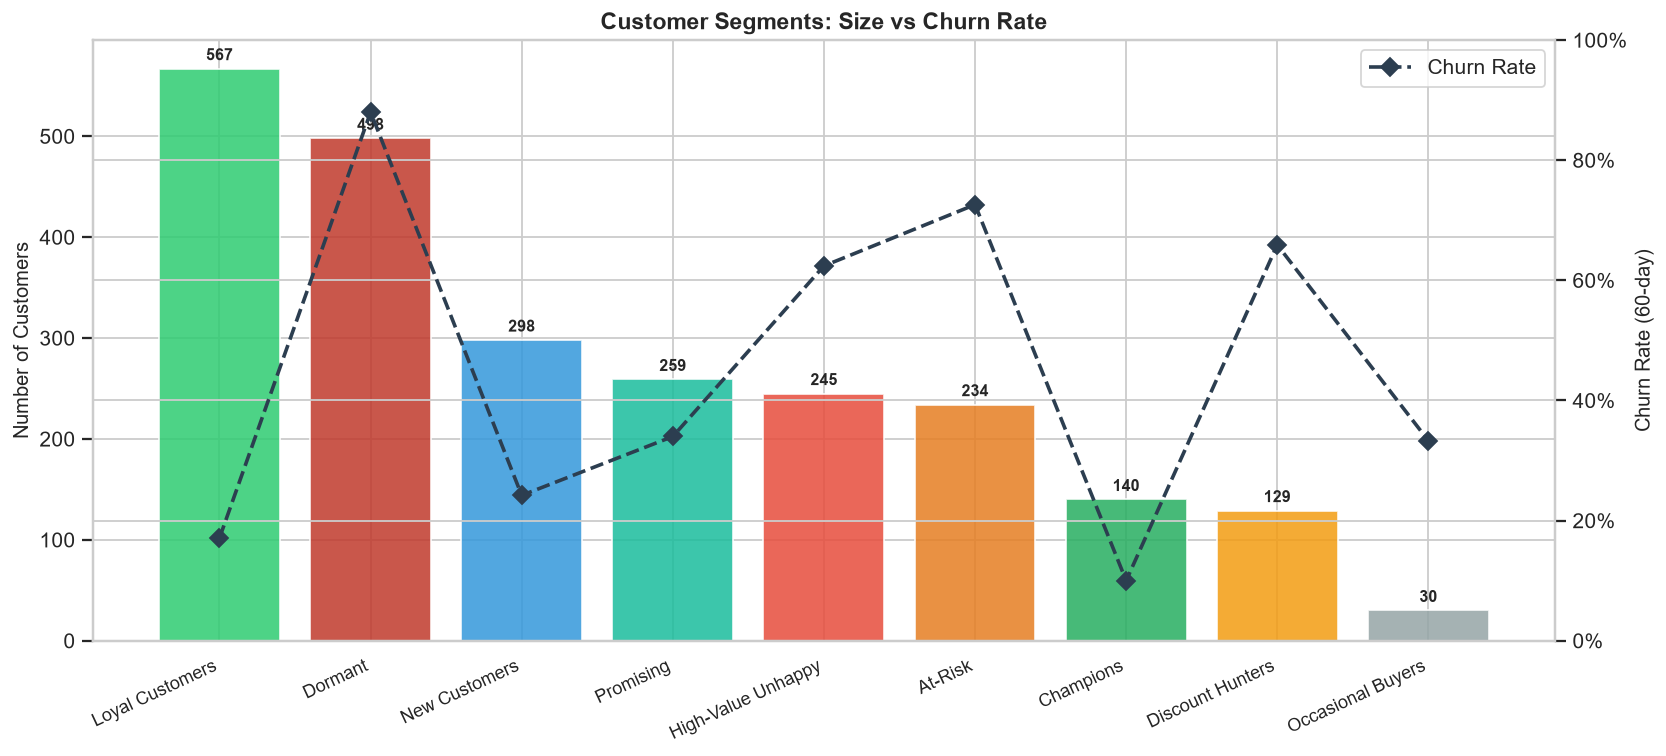

Saved: chart_03_segment_size_churn.png


In [35]:
# ── Chart 1: Segment size + churn rate (dual-axis) ───────────────────────────
seg_plot = seg_summary.sort_values('n_customers', ascending=False).reset_index()

SEGMENT_COLORS = {
    'Champions':          '#27ae60',
    'Loyal Customers':    '#2ecc71',
    'Promising':          '#1abc9c',
    'New Customers':      '#3498db',
    'Occasional Buyers':  '#95a5a6',
    'Discount Hunters':   '#f39c12',
    'At-Risk':            '#e67e22',
    'High-Value Unhappy': '#e74c3c',
    'Dormant':            '#c0392b',
}

fig, ax1 = plt.subplots(figsize=(13, 6), dpi=FIG_DPI)
ax2 = ax1.twinx()

bar_colors = [SEGMENT_COLORS.get(s, '#bdc3c7') for s in seg_plot['segment']]
bars = ax1.bar(seg_plot['segment'], seg_plot['n_customers'], color=bar_colors, alpha=0.85)
ax2.plot(seg_plot['segment'], seg_plot['churn_rate'], 'D--', color='#2c3e50', lw=2, ms=7, label='Churn Rate')

ax1.set_ylabel('Number of Customers', fontsize=11)
ax2.set_ylabel('Churn Rate (60-day)', fontsize=11)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax2.set_ylim(0, 1.0)
ax1.set_xticklabels(seg_plot['segment'], rotation=25, ha='right', fontsize=10)
ax1.set_title('Customer Segments: Size vs Churn Rate', fontweight='bold', fontsize=13)

for bar, n in zip(bars, seg_plot['n_customers']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
             str(n), ha='center', va='bottom', fontsize=9, fontweight='bold')

ax2.legend(loc='upper right')
plt.tight_layout()
file_path = os.path.join(rfm_charts_dir, "chart_03_segment_size_churn.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_03_segment_size_churn.png')

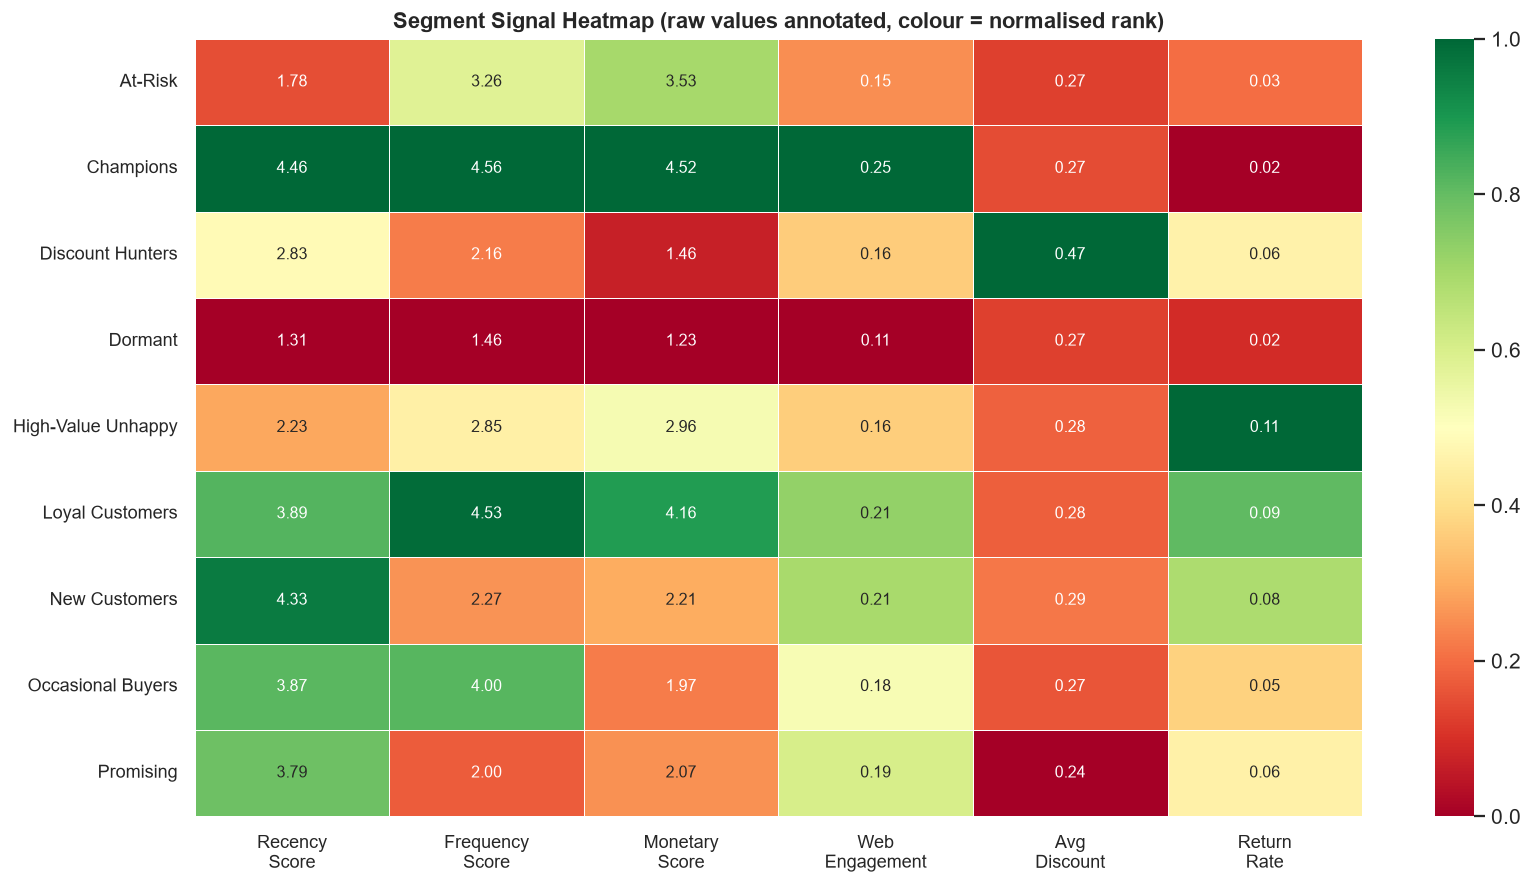

Saved: chart_04_segment_signal_heatmap.png


In [36]:
# ── Chart 2: RFM radar/spider chart per segment ──────────────────────────────
# Normalise R, F, M, web_engagement, neg_ticket_rate to 0-1 for radar
radar_metrics = ['R','F','M','web_engagement_score','avg_discount_180d','return_rate_180d']
radar_labels  = ['Recency\nScore','Frequency\nScore','Monetary\nScore',
                 'Web\nEngagement','Avg\nDiscount','Return\nRate']

seg_radar = rfm.groupby('segment')[radar_metrics].mean()
# Normalise each metric to 0-1 range
seg_radar_norm = (seg_radar - seg_radar.min()) / (seg_radar.max() - seg_radar.min())

# Plot as grouped heatmap (cleaner than overlapping radars)
fig, ax = plt.subplots(figsize=(13, 7), dpi=FIG_DPI)
sns.heatmap(
    seg_radar_norm,
    annot=seg_radar.round(2),
    fmt='.2f',
    cmap='RdYlGn',
    linewidths=0.5,
    ax=ax,
    xticklabels=radar_labels,
    annot_kws={'size': 9},
    vmin=0, vmax=1
)
ax.set_title('Segment Signal Heatmap (raw values annotated, colour = normalised rank)',
             fontweight='bold', fontsize=12)
ax.set_xlabel('')
ax.set_ylabel('')
plt.xticks(rotation=0, fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
file_path = os.path.join(rfm_charts_dir, "chart_04_segment_signal_heatmap.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_04_segment_signal_heatmap.png')

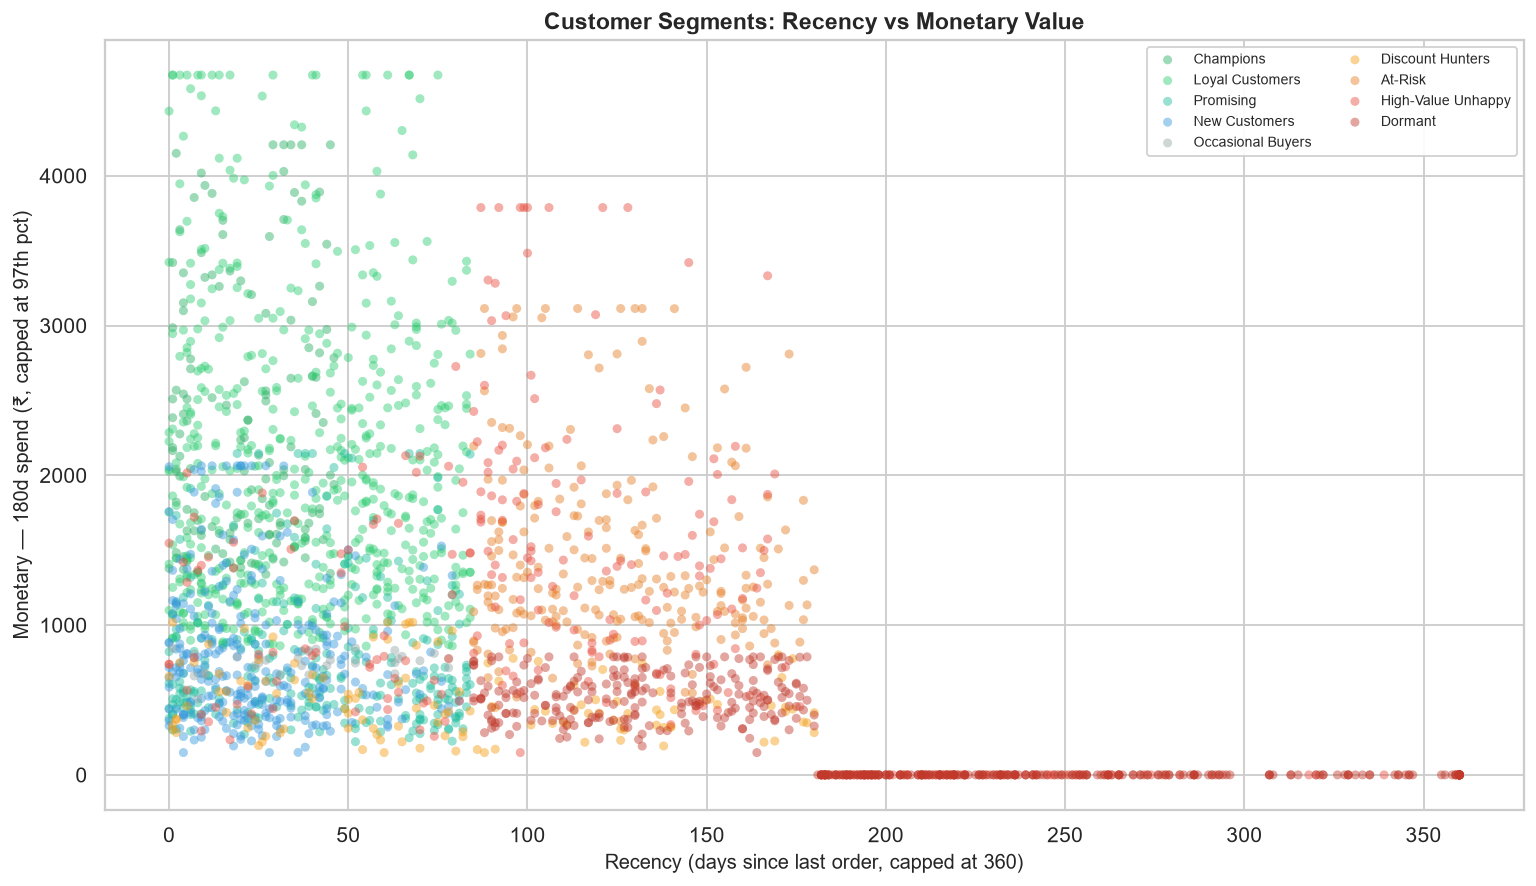

Saved: chart_05_recency_monetary_scatter.png


In [37]:
# ── Chart 3: Recency vs Monetary scatter coloured by segment ─────────────────
fig, ax = plt.subplots(figsize=(12, 7), dpi=FIG_DPI)

for seg, color in SEGMENT_COLORS.items():
    sub = rfm[rfm['segment'] == seg]
    ax.scatter(
        sub['recency_days'].clip(upper=360),
        sub['monetary_180d'].clip(upper=sub['monetary_180d'].quantile(0.97)),
        c=color, label=seg, alpha=0.45, s=25, edgecolors='none'
    )

ax.set_xlabel('Recency (days since last order, capped at 360)', fontsize=11)
ax.set_ylabel('Monetary — 180d spend (₹, capped at 97th pct)', fontsize=11)
ax.set_title('Customer Segments: Recency vs Monetary Value', fontweight='bold', fontsize=13)
ax.legend(loc='upper right', fontsize=8, ncol=2, framealpha=0.9)
plt.tight_layout()
file_path = os.path.join(rfm_charts_dir, "chart_05_recency_monetary_scatter.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_05_recency_monetary_scatter.png')

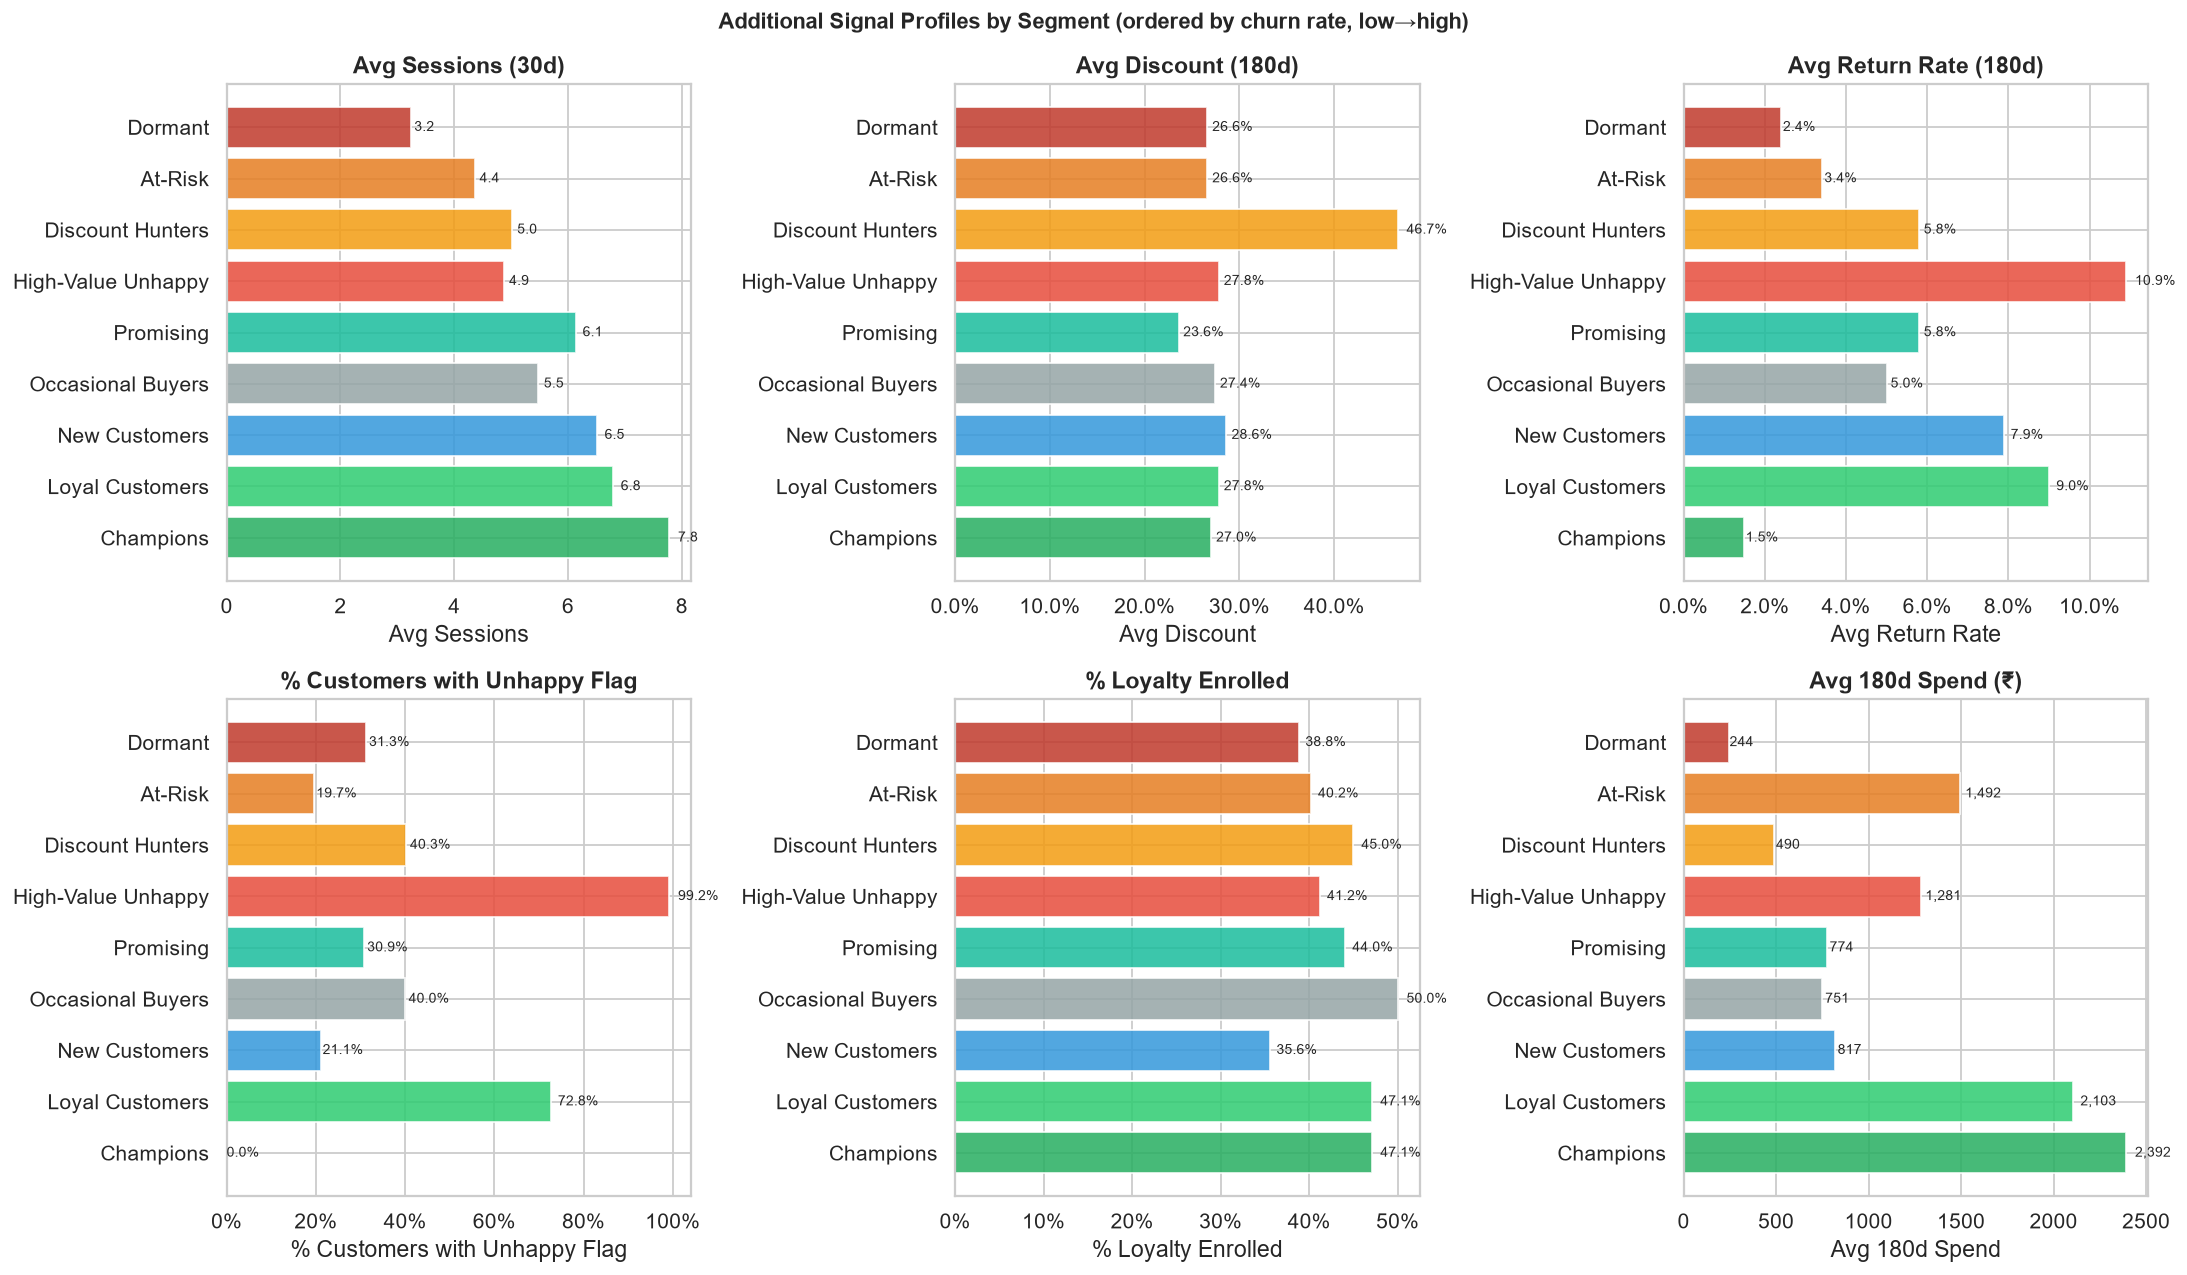

Saved: chart_06_segment_signal_bars.png


In [38]:
# ── Chart 4: Additional signals comparison across segments ───────────────────
fig, axes = plt.subplots(2, 3, figsize=(17, 10), dpi=FIG_DPI)

# Order segments by churn rate
seg_order = seg_summary.sort_values('churn_rate', ascending=True).index.tolist()
colors_ordered = [SEGMENT_COLORS.get(s, '#bdc3c7') for s in seg_order]

metrics = [
    ('avg_sessions',   'Avg Sessions (30d)',          '{:.1f}'),
    ('avg_discount',   'Avg Discount (180d)',          '{:.1%}'),
    ('avg_return_rt',  'Avg Return Rate (180d)',       '{:.1%}'),
    ('pct_unhappy',    '% Customers with Unhappy Flag','{:.1%}'),
    ('pct_loyal_enr',  '% Loyalty Enrolled',           '{:.1%}'),
    ('avg_monetary',   'Avg 180d Spend (₹)',           '{:,.0f}'),
]

for ax, (col, title, fmt) in zip(axes.flat, metrics):
    vals = seg_summary.loc[seg_order, col]
    bars = ax.barh(seg_order, vals, color=colors_ordered, alpha=0.85)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(title.split('(')[0].strip())
    if '%' in fmt:
        ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    for bar, v in zip(bars, vals):
        ax.text(bar.get_width() * 1.02, bar.get_y() + bar.get_height()/2,
                fmt.format(v), va='center', fontsize=8)

plt.suptitle('Additional Signal Profiles by Segment (ordered by churn rate, low→high)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
file_path = os.path.join(rfm_charts_dir, "chart_06_segment_signal_bars.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_06_segment_signal_bars.png')

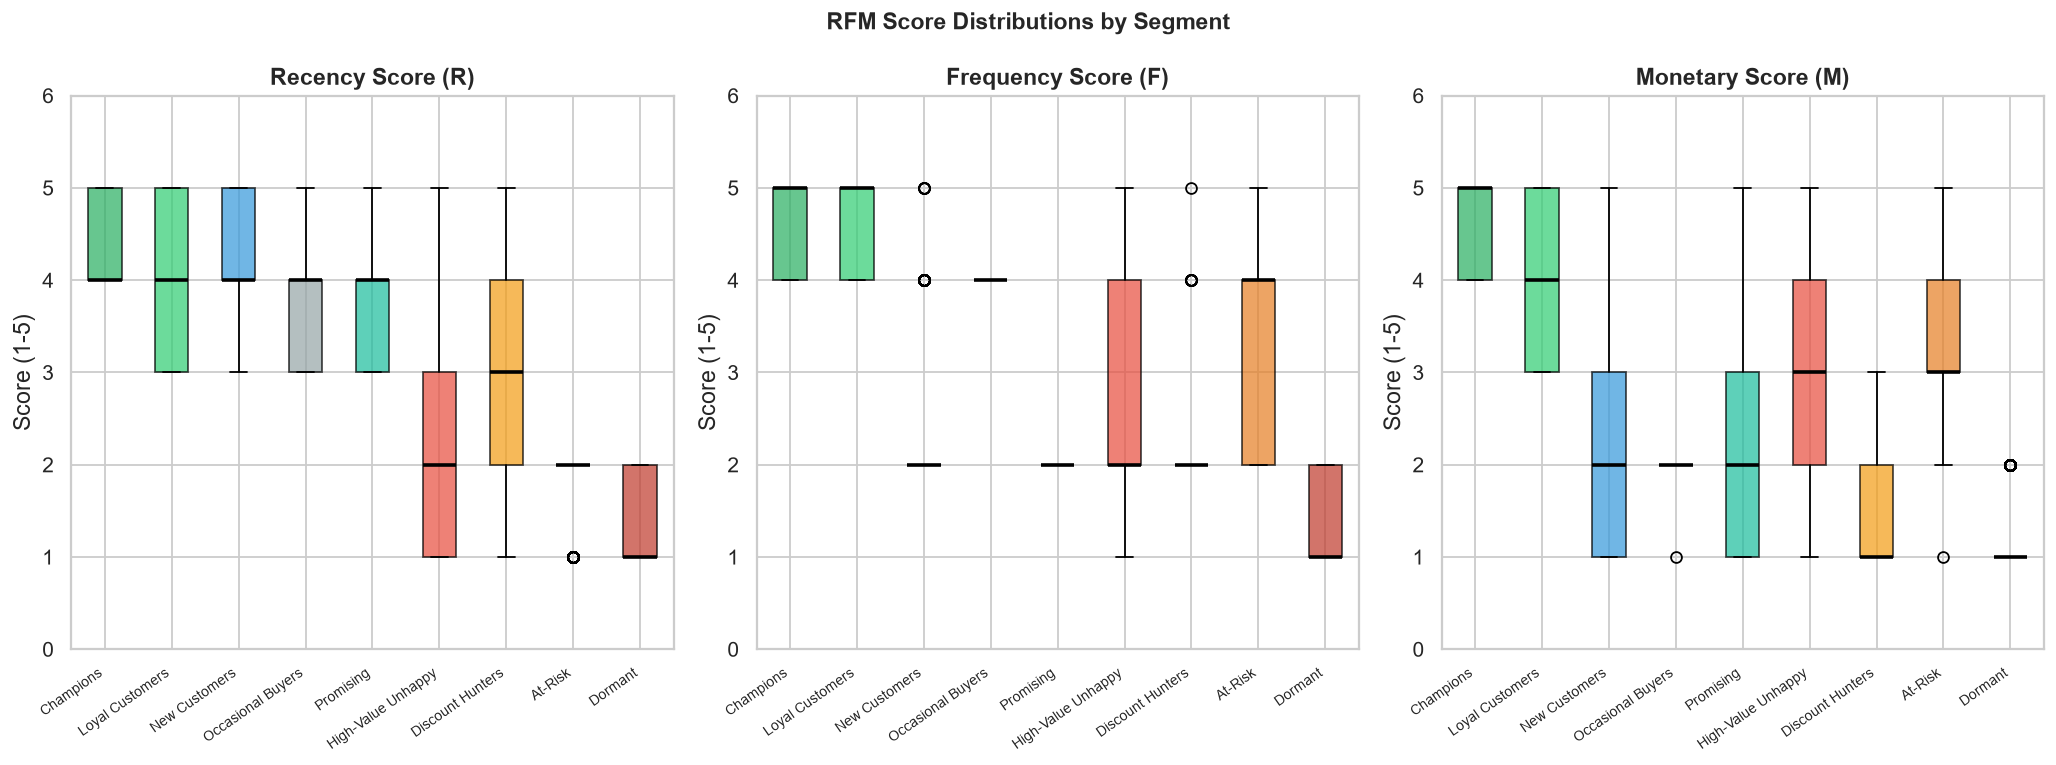

Saved: chart_07_rfm_boxplots_by_segment.png


In [39]:
# ── Chart 5: RFM score box plots by segment ──────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 6), dpi=FIG_DPI)

for ax, score, title in zip(axes, ['R','F','M'],
                             ['Recency Score (R)','Frequency Score (F)','Monetary Score (M)']):
    data_by_seg = [rfm[rfm['segment']==s][score].dropna().values for s in seg_order]
    bp = ax.boxplot(data_by_seg, patch_artist=True,
                    medianprops=dict(color='black', lw=2))
    for patch, color in zip(bp['boxes'], colors_ordered):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax.set_xticklabels(seg_order, rotation=35, ha='right', fontsize=8)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Score (1-5)')
    ax.set_ylim(0, 6)

plt.suptitle('RFM Score Distributions by Segment', fontsize=13, fontweight='bold')
plt.tight_layout()
file_path = os.path.join(rfm_charts_dir, "chart_07_rfm_boxplots_by_segment.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_07_rfm_boxplots_by_segment.png')

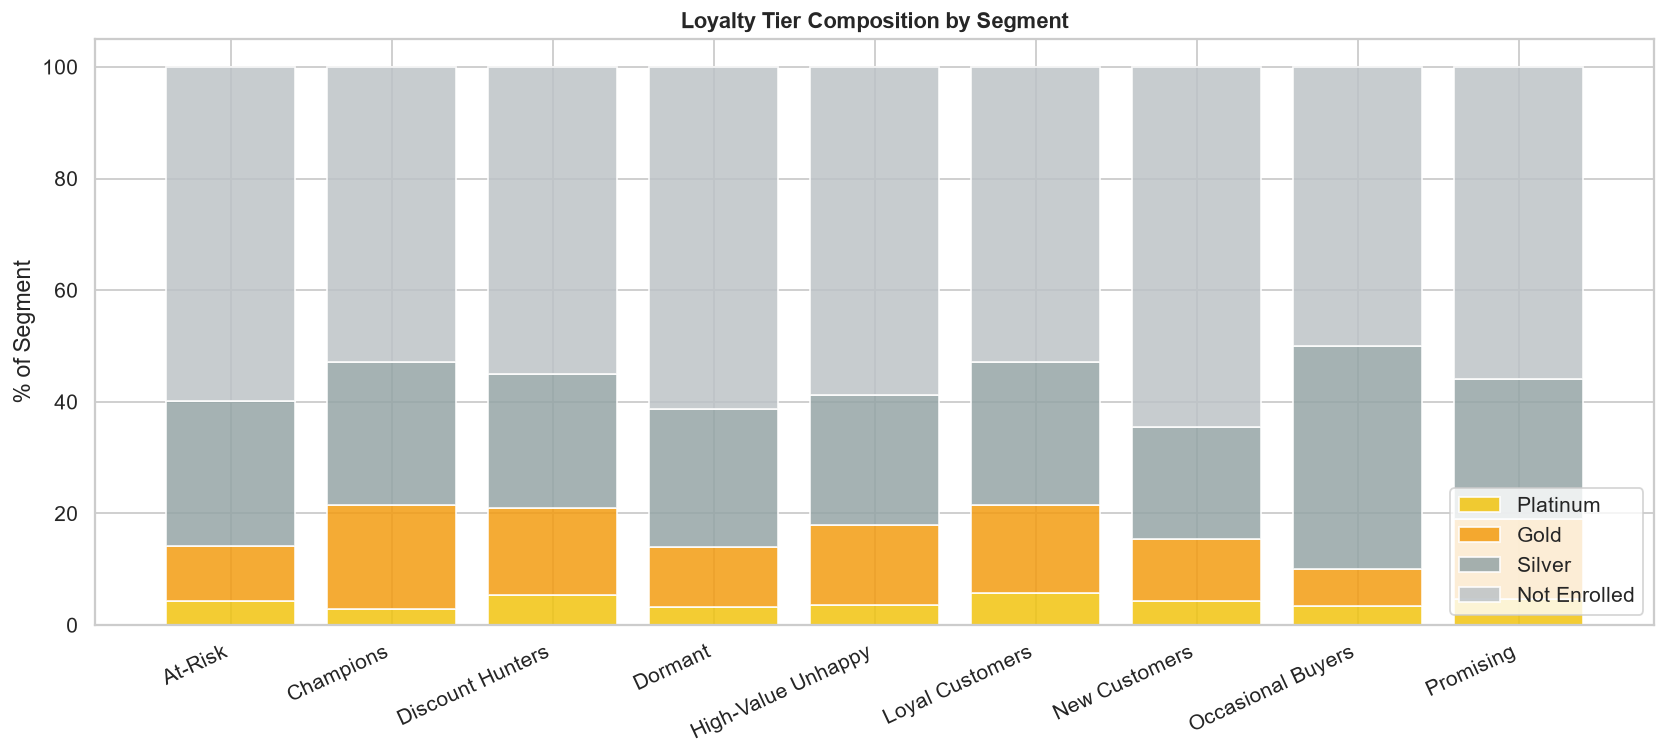

Saved: chart_08_loyalty_composition.png


In [40]:
# ── Chart 6: Loyalty tier composition per segment ────────────────────────────
loyalty_comp = (
    rfm.groupby(['segment','loyalty_tier'], dropna=False).size()
    .reset_index(name='count')
)
loyalty_comp['loyalty_display'] = loyalty_comp['loyalty_tier'].fillna('Not Enrolled')
pivot = loyalty_comp.pivot_table(index='segment', columns='loyalty_display',
                                  values='count', fill_value=0)
# normalise to 100%
pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

cols_order = [c for c in ['Platinum','Gold','Silver','Not Enrolled'] if c in pivot_pct.columns]
colors_loy = {'Platinum':'#f1c40f','Gold':'#f39c12','Silver':'#95a5a6','Not Enrolled':'#bdc3c7'}

fig, ax = plt.subplots(figsize=(13, 6), dpi=FIG_DPI)
bottom = np.zeros(len(pivot_pct))
for tier in cols_order:
    ax.bar(pivot_pct.index, pivot_pct[tier], bottom=bottom,
           label=tier, color=colors_loy[tier], alpha=0.85)
    bottom += pivot_pct[tier].values
ax.set_ylabel('% of Segment')
ax.set_title('Loyalty Tier Composition by Segment', fontweight='bold', fontsize=12)
ax.set_xticklabels(pivot_pct.index, rotation=25, ha='right')
ax.legend(loc='lower right')
plt.tight_layout()
file_path = os.path.join(rfm_charts_dir, "chart_08_loyalty_composition.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_08_loyalty_composition.png')

In [41]:
# ── Full segment summary table ────────────────────────────────────────────────
full_profile = rfm.groupby('segment').agg(
    n_customers          = ('customer_id',        'count'),
    churn_rate           = ('churn_next_60d',      'mean'),
    avg_recency_days     = ('recency_days',        'mean'),
    avg_frequency_180d   = ('frequency_180d',     'mean'),
    avg_monetary_180d    = ('monetary_180d',      'mean'),
    avg_lifetime_spend   = ('lifetime_spend',     'mean'),
    avg_rfm_score        = ('rfm_score',          'mean'),
    avg_discount         = ('avg_discount_180d',  'mean'),
    avg_return_rate      = ('return_rate_180d',   'mean'),
    avg_sessions_30d     = ('sessions_30d',       'mean'),
    avg_last_visit_days  = ('last_visit_days_ago','mean'),
    avg_web_engagement   = ('web_engagement_score','mean'),
    pct_unhappy          = ('unhappy_flag',       'mean'),
    pct_discount_hunter  = ('discount_hunter_flag','mean'),
    pct_high_return      = ('high_return_flag',   'mean'),
    pct_loyalty_enrolled = ('loyalty_enrolled',   'mean'),
    pct_of_base          = ('customer_id',        lambda x: len(x)/len(rfm)*100),
).round(3).sort_values('churn_rate', ascending=False)

full_profile.to_csv(os.path.join(rfm_tables_dir, "full_segment_profile.csv"))
print('Full segment profile:')
print(full_profile.to_string())
print('\nSaved: outputs/rfm/tables/full_segment_profile.csv')

Full segment profile:
                    n_customers  churn_rate  avg_recency_days  avg_frequency_180d  avg_monetary_180d  avg_lifetime_spend  avg_rfm_score  avg_discount  avg_return_rate  avg_sessions_30d  avg_last_visit_days  avg_web_engagement  pct_unhappy  pct_discount_hunter  pct_high_return  pct_loyalty_enrolled  pct_of_base
segment                                                                                                                                                                                                                                                                                                                
Dormant                     498      0.8800          195.8390              0.4620           243.7160           1647.9850         1.3330        0.2660           0.0240            3.2350              37.4780              0.1140       0.3130               0.0000           0.0240                0.3880      20.7500
At-Risk                     234      0.726

## 7. Budget Prioritisation

We calculate **expected revenue at risk** per segment:  
`revenue_at_risk = n_customers × churn_rate × avg_monetary_180d`  

This tells us how much 180-day spend is projected to be lost if no intervention is made.

In [42]:
# ── Revenue at risk and cost-to-reach estimates ───────────────────────────────
TOTAL_BUDGET = 50_000  # ₹50,000 illustrative campaign budget

# Intervention cost estimates per customer (illustrative)
INTERVENTION_COST = {
    'Champions':          5,   # Low-cost: loyalty reward notification
    'Loyal Customers':    8,   # Email personalised offer
    'Promising':          10,  # Welcome series + category intro
    'New Customers':      12,  # Onboarding + first-repeat offer
    'Occasional Buyers':  15,  # Targeted email + small discount
    'Discount Hunters':   8,   # No-discount; loyalty pitch
    'At-Risk':            20,  # High-value outreach + incentive
    'High-Value Unhappy': 25,  # Personal apology + resolution + offer
    'Dormant':            18,  # Winback campaign + deep discount
}

budget_df = full_profile[['n_customers','churn_rate','avg_monetary_180d']].copy()
budget_df['revenue_at_risk']  = (budget_df['n_customers'] * budget_df['churn_rate'] * budget_df['avg_monetary_180d']).round(0)
budget_df['cost_per_customer'] = budget_df.index.map(INTERVENTION_COST)
budget_df['total_cost']       = (budget_df['n_customers'] * budget_df['cost_per_customer']).round(0)
budget_df['roi_ratio']        = (budget_df['revenue_at_risk'] / budget_df['total_cost'].replace(0, np.nan)).round(1)
budget_df['priority']         = budget_df['roi_ratio'].rank(ascending=False).astype(int)
budget_df = budget_df.sort_values('priority')

print(f'Total campaign budget: ₹{TOTAL_BUDGET:,}')
print(f'\n── Revenue at Risk & Budget Allocation ─────────────────────────────────')
print(budget_df[['n_customers','churn_rate','avg_monetary_180d',
                  'revenue_at_risk','cost_per_customer','total_cost','roi_ratio','priority']].to_string())

output_path = os.path.join(rfm_summary_metrics_dir, 'budget_prioritisation.csv')
os.makedirs(os.path.dirname(output_path), exist_ok=True)
budget_df.to_csv(output_path, index=False)
print('\nSaved: outputs/rfm/summary_metrics/budget_prioritisation.csv')

Total campaign budget: ₹50,000

── Revenue at Risk & Budget Allocation ─────────────────────────────────
                    n_customers  churn_rate  avg_monetary_180d  revenue_at_risk  cost_per_customer  total_cost  roi_ratio  priority
segment                                                                                                                            
At-Risk                     234      0.7260          1492.3970      253534.0000                 20        4680    54.2000         1
Champions                   140      0.1000          2392.1960       33491.0000                  5         700    47.8000         2
Loyal Customers             567      0.1710          2102.6540      203867.0000                  8        4536    44.9000         3
Discount Hunters            129      0.6590           490.0110       41656.0000                  8        1032    40.4000         4
High-Value Unhappy          245      0.6240          1281.1040      195855.0000                 25     

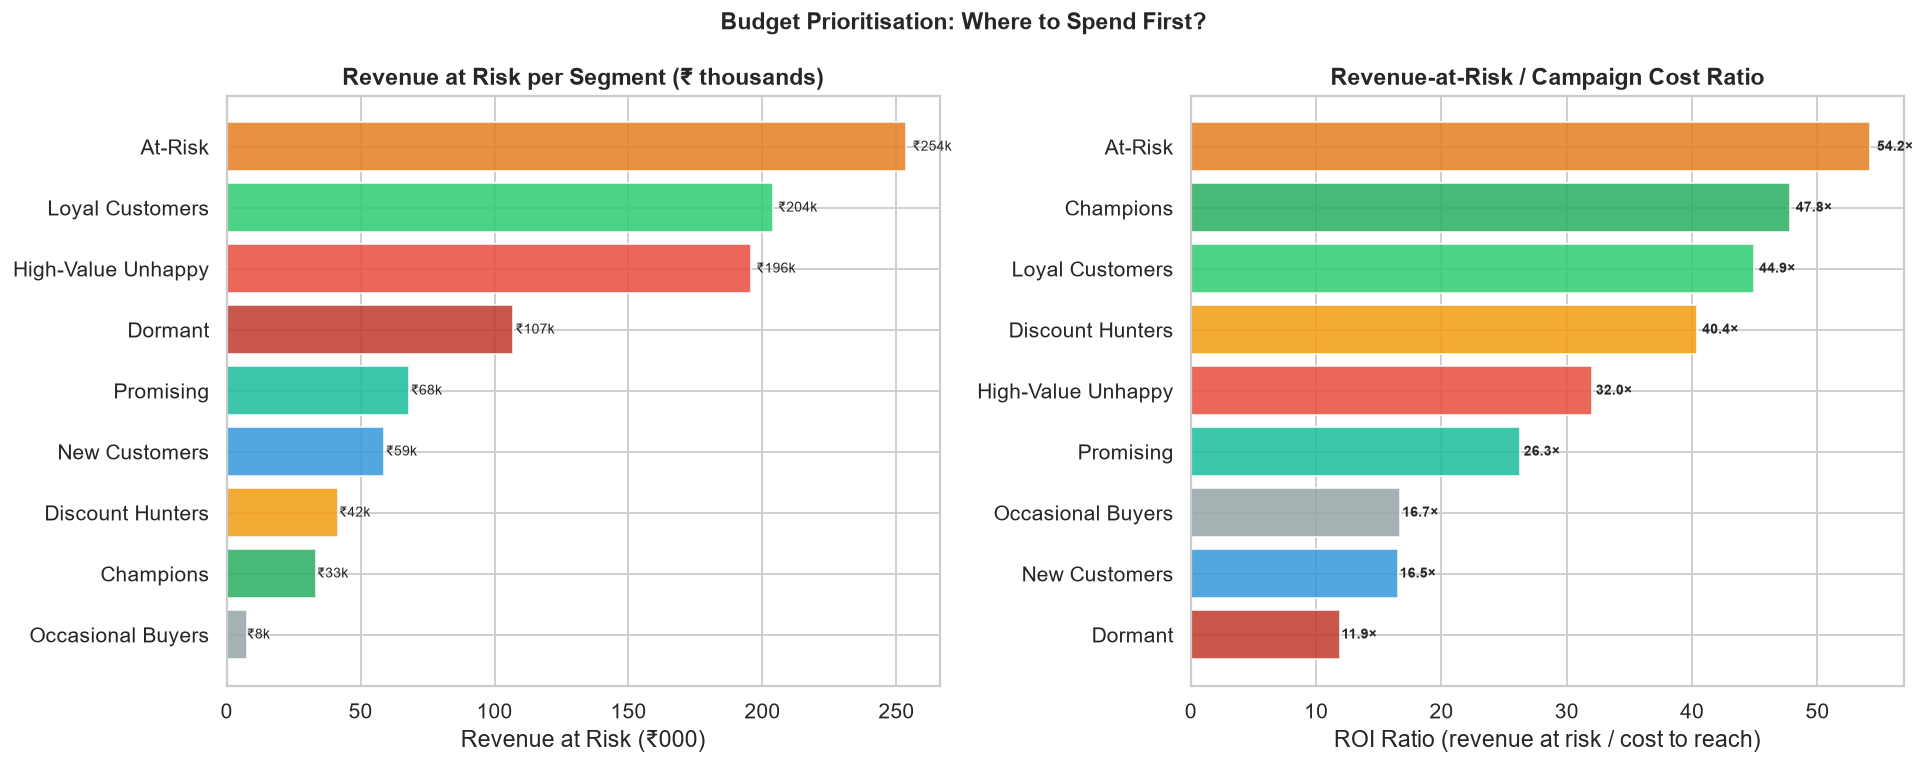

Saved: chart_09_budget_prioritisation.png


In [43]:
# ── Chart 7: Revenue at risk vs total cost per segment ───────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=FIG_DPI)

bd = budget_df.sort_values('revenue_at_risk', ascending=True)
seg_colors_bd = [SEGMENT_COLORS.get(s, '#bdc3c7') for s in bd.index]

# Revenue at risk
axes[0].barh(bd.index, bd['revenue_at_risk']/1000, color=seg_colors_bd, alpha=0.85)
axes[0].set_title('Revenue at Risk per Segment (₹ thousands)', fontweight='bold')
axes[0].set_xlabel('Revenue at Risk (₹000)')
for i, (seg, row) in enumerate(bd.iterrows()):
    axes[0].text(row['revenue_at_risk']/1000 * 1.01, i, f'₹{row["revenue_at_risk"]/1000:,.0f}k',
                 va='center', fontsize=8)

# ROI ratio
bd2 = budget_df.sort_values('roi_ratio', ascending=True)
seg_colors_bd2 = [SEGMENT_COLORS.get(s, '#bdc3c7') for s in bd2.index]
axes[1].barh(bd2.index, bd2['roi_ratio'], color=seg_colors_bd2, alpha=0.85)
axes[1].set_title('Revenue-at-Risk / Campaign Cost Ratio', fontweight='bold')
axes[1].set_xlabel('ROI Ratio (revenue at risk / cost to reach)')
for i, (seg, row) in enumerate(bd2.iterrows()):
    axes[1].text(row['roi_ratio'] * 1.01, i, f'{row["roi_ratio"]:.1f}×',
                 va='center', fontsize=8, fontweight='bold')

plt.suptitle('Budget Prioritisation: Where to Spend First?', fontsize=13, fontweight='bold')
plt.tight_layout()
file_path = os.path.join(rfm_charts_dir, "chart_09_budget_prioritisation.png")
plt.savefig(file_path, dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print('Saved: chart_09_budget_prioritisation.png')

In [44]:
# ── Cumulative budget allocation ─────────────────────────────────────────────
bd_cumul = budget_df.sort_values('roi_ratio', ascending=False).copy()
bd_cumul['cumul_cost'] = bd_cumul['total_cost'].cumsum()
bd_cumul['within_budget'] = bd_cumul['cumul_cost'] <= TOTAL_BUDGET

print(f'\n── Cumulative budget allocation (budget = ₹{TOTAL_BUDGET:,}) ──────────────')
print(bd_cumul[['n_customers','total_cost','cumul_cost','within_budget','roi_ratio']].to_string())


── Cumulative budget allocation (budget = ₹50,000) ──────────────
                    n_customers  total_cost  cumul_cost  within_budget  roi_ratio
segment                                                                          
At-Risk                     234        4680        4680           True    54.2000
Champions                   140         700        5380           True    47.8000
Loyal Customers             567        4536        9916           True    44.9000
Discount Hunters            129        1032       10948           True    40.4000
High-Value Unhappy          245        6125       17073           True    32.0000
Promising                   259        2590       19663           True    26.3000
Occasional Buyers            30         450       20113           True    16.7000
New Customers               298        3576       23689           True    16.5000
Dormant                     498        8964       32653           True    11.9000


## 8. Manual Review — Edge Cases

Customers where the segmentation rule places them in one bucket but their full signal profile suggests nuance.

In [45]:
# ── Identify edge-case candidates ─────────────────────────────────────────────

# Case type 1: High-value but borderline recency (R=2, M=4/5)
edge1 = rfm[(rfm['R']==2) & (rfm['M']>=4) & (rfm['segment']=='At-Risk')].head(3)

# Case type 2: Discount hunters who are actually loyal (F=4/5)
edge2 = rfm[(rfm['discount_hunter_flag']==1) & (rfm['F']>=4)].head(3)

# Case type 3: Champions flagged unhappy (excluded from Champions, landed elsewhere)
edge3 = rfm[(rfm['R']>=4) & (rfm['F']>=4) & (rfm['M']>=4) & (rfm['unhappy_flag']==1)].head(2)

# Case type 4: Promising customers with 0 web sessions (engaged offline?)
edge4 = rfm[(rfm['segment']=='Promising') & (rfm['sessions_30d']==0)].head(2)

# Case type 5: Dormant but recently clicked a campaign email
edge5 = rfm[(rfm['segment']=='Dormant') & (rfm['campaign_clicks_30d']>=1)].head(2)

edge_cases = pd.concat([edge1, edge2, edge3, edge4, edge5]).drop_duplicates('customer_id').head(15)

review_cols = ['customer_id','segment','R','F','M','rfm_score',
               'recency_days','frequency_180d','monetary_180d','lifetime_spend',
               'return_rate_180d','avg_discount_180d','sessions_30d','last_visit_days_ago',
               'ticket_count_all','avg_sentiment','unhappy_flag','discount_hunter_flag',
               'loyalty_tier','days_since_signup','churn_next_60d']

edge_display = edge_cases[review_cols].reset_index(drop=True)
print('Edge case customer profiles:')
print(edge_display.to_string())

edge_display.to_csv(os.path.join(rfm_tables_dir, "manual_review_candidates.csv"), index=False)
print('\nSaved: outputs/rfm/tables/manual_review_candidates.csv')

Edge case customer profiles:
   customer_id          segment      R      F      M  rfm_score  recency_days  frequency_180d  monetary_180d  lifetime_spend  return_rate_180d  avg_discount_180d  sessions_30d  last_visit_days_ago  ticket_count_all  avg_sentiment  unhappy_flag  discount_hunter_flag loyalty_tier  days_since_signup  churn_next_60d
0    CUST00004          At-Risk 2.0000 2.0000 4.0000     2.6700           131               1      1604.0400       1604.0400            0.0000             0.1600             1                   14                 0            NaN             0                     0          NaN                168               1
1    CUST00057          At-Risk 2.0000 2.0000 4.0000     2.6700           136               1      1713.3400       2510.8300            0.0000             0.1400             7                   29                 0            NaN             0                     0          NaN                250               1
2    CUST00072          At-Ri

## 9. Export — `segments.csv`

In [46]:
export_cols = [
    'customer_id', 'segment',
    # RFM scores
    'R', 'F', 'M', 'rfm_score', 'rfm_label',
    # Core RFM features
    'recency_days', 'frequency_180d', 'monetary_180d', 'avg_order_value', 'lifetime_spend',
    # Order behaviour
    'return_rate_180d', 'avg_discount_180d', 'avg_rating_180d', 'category_diversity',
    # Support signals
    'ticket_count_all', 'avg_sentiment', 'neg_ticket_rate', 'avg_resolution_hrs', 'reopened_rate',
    # Web/app signals
    'sessions_30d', 'product_views_30d', 'cart_adds_30d', 'wishlist_adds_30d',
    'abandoned_carts_30d', 'email_opens_30d', 'campaign_clicks_30d', 'last_visit_days_ago',
    'web_engagement_score',
    # Profile
    'loyalty_tier', 'loyalty_enrolled', 'acquisition_channel', 'city_tier',
    'age_group', 'preferred_category', 'marketing_consent', 'days_since_signup',
    # Flags
    'discount_hunter_flag', 'high_return_flag', 'unhappy_flag',
    'new_customer_flag', 'low_web_flag',
    # Campaign context
    'last_campaign_received', 'manual_priority_bucket',
    # Label (for evaluation only — not to be used as a feature)
    'churn_next_60d', 'split',
]

segments_out = rfm[[c for c in export_cols if c in rfm.columns]].copy()

if 'segment' in segments_out.columns:
    segments_out.rename(columns={'segment':'segment_name'}, inplace=True)

segments_out = segments_out.round(4)

segments_out.to_csv(
    os.path.join(rfm_output_dir, 'segments.csv'),
    index=False
)
print(f'Exported segments.csv: {segments_out.shape[0]:,} rows × {segments_out.shape[1]} columns')
print(f'\nSegment distribution in export:')
print(segments_out['segment_name'].value_counts().to_string())

# Verify saved file
check = pd.read_csv(os.path.join(rfm_output_dir, 'segments.csv'))
print("\nColumns in saved CSV:")
print(check.columns.tolist())

Exported segments.csv: 2,400 rows × 47 columns

Segment distribution in export:
segment_name
Loyal Customers       567
Dormant               498
New Customers         298
Promising             259
High-Value Unhappy    245
At-Risk               234
Champions             140
Discount Hunters      129
Occasional Buyers      30



Columns in saved CSV:
['customer_id', 'segment_name', 'R', 'F', 'M', 'rfm_score', 'rfm_label', 'recency_days', 'frequency_180d', 'monetary_180d', 'avg_order_value', 'lifetime_spend', 'return_rate_180d', 'avg_discount_180d', 'avg_rating_180d', 'category_diversity', 'ticket_count_all', 'avg_sentiment', 'neg_ticket_rate', 'avg_resolution_hrs', 'reopened_rate', 'sessions_30d', 'product_views_30d', 'cart_adds_30d', 'wishlist_adds_30d', 'abandoned_carts_30d', 'email_opens_30d', 'campaign_clicks_30d', 'last_visit_days_ago', 'web_engagement_score', 'loyalty_tier', 'loyalty_enrolled', 'acquisition_channel', 'city_tier', 'age_group', 'preferred_category', 'marketing_consent', 'days_since_signup', 'discount_hunter_flag', 'high_return_flag', 'unhappy_flag', 'new_customer_flag', 'low_web_flag', 'last_campaign_received', 'manual_priority_bucket', 'churn_next_60d', 'split']


In [47]:
# ── Final summary printout ────────────────────────────────────────────────────
print('=' * 70)
print('  PART 2 — SEGMENTATION SUMMARY')
print('=' * 70)
print(f'  Total customers:       {len(rfm):,}')
print(f'  Overall churn rate:    {rfm["churn_next_60d"].mean():.1%}')
print(f'  RFM window:            {RFM_WINDOW} days ({RFM_START.date()} → {SNAPSHOT.date()})')
print(f'  Segments created:      {rfm["segment"].nunique()}')
print()
print(f'  {"Segment":<22} {"N":>6} {"% Base":>8} {"Churn%":>8} {"Avg M₹":>10} {"Rev@Risk":>12}')
print('  ' + '-' * 70)
for seg in budget_df.sort_values('priority').index:
    row = budget_df.loc[seg]
    fp  = full_profile.loc[seg]
    print(f'  {seg:<22} {int(fp["n_customers"]):>6} {fp["pct_of_base"]:>7.1f}% '
          f'{fp["churn_rate"]:>7.1%} {fp["avg_monetary_180d"]:>10,.0f} '
          f'₹{row["revenue_at_risk"]:>10,.0f}')
print('=' * 70)
print(f'  Total revenue at risk: ₹{budget_df["revenue_at_risk"].sum():,.0f}')
print('=' * 70)

  PART 2 — SEGMENTATION SUMMARY
  Total customers:       2,400
  Overall churn rate:    47.0%
  RFM window:            180 days (2025-04-03 → 2025-09-30)
  Segments created:      9

  Segment                     N   % Base   Churn%     Avg M₹     Rev@Risk
  ----------------------------------------------------------------------
  At-Risk                   234     9.8%   72.6%      1,492 ₹   253,534
  Champions                 140     5.8%   10.0%      2,392 ₹    33,491
  Loyal Customers           567    23.6%   17.1%      2,103 ₹   203,867
  Discount Hunters          129     5.4%   65.9%        490 ₹    41,656
  High-Value Unhappy        245    10.2%   62.4%      1,281 ₹   195,855
  Promising                 259    10.8%   34.0%        774 ₹    68,148
  Occasional Buyers          30     1.2%   33.3%        751 ₹     7,500
  New Customers             298    12.4%   24.2%        817 ₹    58,894
  Dormant                   498    20.8%   88.0%        244 ₹   106,806
  Total revenue at risk